# HYCOM流苏分量UU数据裁切与转换工具

本 notebook 实现：

1. 将 HYCOM_2025_U_ALL.nc 仅做范围裁切，保留原始网格特征
2. 在写入 DFS3 时再统一做规则网格化和深度插值
3. 保留几个检查窗口，方便核对坐标范围、垂向剖面和二维层面结果 (todo)

**处理原则**
- 裁切阶段不做网格规范化
- 陆地空值保持 NaN，不写成 0
- 允许在中间步骤查看异常值、坐标范围和插值前后对比


In [1]:
import numpy as np
import netCDF4 as nc
from scipy.interpolate import interp1d, griddata
import matplotlib.pyplot as plt
import mikeio
from mikeio import Dfs3
from mikeio.eum import ItemInfo, EUMUnit, EUMType
from mikeio import Grid3D
import warnings
import os
import time
import pandas as pd
from datetime import datetime, timedelta

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120

print('库加载完成')


库加载完成


In [7]:

# 公共函数：给后续单元复用
def sanitize_array(arr, fill_value=None, missing_value=None, vmin=None, vmax=None):
    """把数据统一转成 float32，并把 fill/missing/非法值变成 NaN。"""
    x = np.array(arr, dtype=np.float32, copy=True)
    x[~np.isfinite(x)] = np.nan
    if fill_value is not None:
        x[np.isclose(x, fill_value)] = np.nan
    if missing_value is not None:
        x[np.isclose(x, missing_value)] = np.nan
    if vmin is not None:
        x[x < vmin] = np.nan
    if vmax is not None:
        x[x > vmax] = np.nan
    return x

def print_grid_summary(name, lon, lat, depth):
    lon = np.asarray(lon, dtype=np.float32)
    lat = np.asarray(lat, dtype=np.float32)
    depth = np.asarray(depth, dtype=np.float32)
    print(f'{name}:')
    print(f'  lon: {lon.size} 个点, 范围 [{np.nanmin(lon):.6f}, {np.nanmax(lon):.6f}]')
    print(f'  lat: {lat.size} 个点, 范围 [{np.nanmin(lat):.6f}, {np.nanmax(lat):.6f}]')
    print(f'  depth: {depth.size} 层, 范围 [{np.nanmin(depth):.3f}, {np.nanmax(depth):.3f}]')
    if lon.size > 1:
        dlon = np.diff(lon)
        print(f'  lon 间隔: min={np.nanmin(dlon):.6f}, max={np.nanmax(dlon):.6f}')
    if lat.size > 1:
        dlat = np.diff(lat)
        print(f'  lat 间隔: min={np.nanmin(dlat):.6f}, max={np.nanmax(dlat):.6f}')
    if depth.size > 1:
        ddep = np.diff(depth)
        print(f'  depth 间隔: min={np.nanmin(ddep):.6f}, max={np.nanmax(ddep):.6f}')

def regular_axis(vmin, vmax, step):
    """生成规则坐标轴：x_i = x_0 + i * Δx"""
    start = np.floor(vmin / step) * step
    end = np.ceil(vmax / step) * step
    axis = np.arange(start, end + 0.5 * step, step, dtype=np.float32)
    return np.round(axis, 8)

def nearest_ij(lon_1d, lat_1d, target_lon, target_lat):
    """返回一维经纬度数组中最接近目标点的索引。"""
    lon_1d = np.asarray(lon_1d, dtype=np.float32)
    lat_1d = np.asarray(lat_1d, dtype=np.float32)
    i = int(np.nanargmin(np.abs(lon_1d - target_lon)))
    j = int(np.nanargmin(np.abs(lat_1d - target_lat)))
    return i, j

def plot_profile(depth_src, profile_src, depth_tgt, profile_tgt, title=''):
    plt.figure(figsize=(6, 6))
    plt.plot(profile_src, depth_src, 'o-', label='裁切后原始剖面')
    plt.plot(profile_tgt, depth_tgt, 's-', label='插值后剖面')
    plt.gca().invert_yaxis()
    plt.xlabel('U (m/s)')
    plt.ylabel('Depth (m)')
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

def copy_variable_attributes(dst_var, src_var):
    """复制源变量的所有属性到目标变量"""
    for attr_name in src_var.ncattrs():
        if attr_name == '_FillValue' or attr_name == 'missing_value':
            continue
        attr_value = getattr(src_var, attr_name)
        try:
            dst_var.setncattr(attr_name, attr_value)
        except Exception:
            pass

def copy_global_attributes(dst_ds, src_ds):
    """复制源数据集的所有全局属性"""
    for attr_name in src_ds.ncattrs():
        attr_value = getattr(src_ds, attr_name)
        try:
            dst_ds.setncattr(attr_name, attr_value)
        except Exception:
            pass



## 参数设置


In [8]:
INPUT_FILE = r'c:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL.nc'
OUTPUT_NC_FILE = r'c:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL_small.nc'
OUTPUT_DFS3_FILE = r'c:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL_small.dfs3'

LON_MIN, LON_MAX = 117.6, 119.0
LAT_MIN, LAT_MAX = 23.85, 24.80
DEPTH_MIN, DEPTH_MAX = 0, 60

DFS3_LON_INTERVAL = 0.08
DFS3_LAT_INTERVAL = 0.04
DFS3_DEPTH_INTERVAL = 2.0

SALI_MIN = 0.0
SALI_MAX = 40.0

# 检查窗口参数
CHECK_TIME_INDEX = 4
CHECK_LON = 118.30
CHECK_LAT = 24.30
CHECK_DEPTH_LAYER = 0  # 0 表示表层
SHOW_SAMPLES = True


## 裁切NC文件


In [9]:
try:
    from tqdm import tqdm
except ImportError:
    tqdm = None

if os.path.exists(OUTPUT_NC_FILE):
    print(f'文件已存在: {OUTPUT_NC_FILE}')
else:
    ds_orig = nc.Dataset(INPUT_FILE, 'r')
    ds_orig.set_auto_mask(False)
    ds_orig.set_auto_scale(False)

    lon_orig   = np.array(ds_orig.variables['lon'][:],   dtype=np.float32)
    lat_orig   = np.array(ds_orig.variables['lat'][:],   dtype=np.float32)
    depth_orig = np.array(ds_orig.variables['depth'][:], dtype=np.float32)
    time_orig  = np.array(ds_orig.variables['time'][:],  dtype=np.float64)
    u_orig = ds_orig.variables['water_u']

    lon_orig_var   = ds_orig.variables['lon']
    lat_orig_var   = ds_orig.variables['lat']
    depth_orig_var = ds_orig.variables['depth']
    time_orig_var  = ds_orig.variables['time']

    lon_indices   = np.where((lon_orig >= LON_MIN) & (lon_orig <= LON_MAX))[0]
    lat_indices   = np.where((lat_orig >= LAT_MIN) & (lat_orig <= LAT_MAX))[0]
    depth_indices = np.where((depth_orig >= DEPTH_MIN) & (depth_orig <= DEPTH_MAX))[0]

    lon_small   = lon_orig[lon_indices]
    lat_small   = lat_orig[lat_indices]
    depth_small = depth_orig[depth_indices]

    # ---- 关键：判断是否连续索引（用于 slice hyperslab 读取）----
    lon_contig   = (lon_indices.size > 0) and np.all(np.diff(lon_indices) == 1)
    lat_contig   = (lat_indices.size > 0) and np.all(np.diff(lat_indices) == 1)
    depth_contig = (depth_indices.size > 0) and np.all(np.diff(depth_indices) == 1)

    ds_small_new = nc.Dataset(OUTPUT_NC_FILE, 'w', format='NETCDF4')
    copy_global_attributes(ds_small_new, ds_orig)

    ds_small_new.createDimension('time', None)
    ds_small_new.createDimension('depth', len(depth_small))
    ds_small_new.createDimension('lat', len(lat_small))
    ds_small_new.createDimension('lon', len(lon_small))

    time_var_new = ds_small_new.createVariable('time',  'f8', ('time',))
    time_var_new[:] = time_orig
    copy_variable_attributes(time_var_new, time_orig_var)

    lon_var_new = ds_small_new.createVariable('lon',   'f4', ('lon',))
    lon_var_new[:] = lon_small
    copy_variable_attributes(lon_var_new, lon_orig_var)

    lat_var_new = ds_small_new.createVariable('lat',   'f4', ('lat',))
    lat_var_new[:] = lat_small
    copy_variable_attributes(lat_var_new, lat_orig_var)

    depth_var_new = ds_small_new.createVariable('depth', 'f4', ('depth',))
    depth_var_new[:] = depth_small
    copy_variable_attributes(depth_var_new, depth_orig_var)

    vtemp = ds_small_new.createVariable(
        'water_u', 'f4', ('time', 'depth', 'lat', 'lon'),
        fill_value=np.nan,
        chunksizes=(1, len(depth_small), len(lat_small), min(len(lon_small), 256))
    )
    copy_variable_attributes(vtemp, u_orig)

    fv = getattr(u_orig, '_FillValue', None)
    mv = getattr(u_orig, 'missing_value', None)

    nt = len(time_orig)

    # ✅ 进度条迭代器（tqdm 可用就用；否则退化为 range）
    iterator = range(nt)
    if tqdm is not None:
        iterator = tqdm(iterator, total=nt, desc="裁切 water_u", unit="step", dynamic_ncols=True)

    t0 = time.time()

    if lon_contig and lat_contig and depth_contig:
        lo0, lo1 = lon_indices[0],   lon_indices[-1] + 1
        la0, la1 = lat_indices[0],   lat_indices[-1] + 1
        de0, de1 = depth_indices[0], depth_indices[-1] + 1

        for i in iterator:
            sub = u_orig[i, de0:de1, la0:la1, lo0:lo1]  # hyperslab 直接读子块
            arr = sanitize_array(sub, fv, mv)
            vtemp[i, :, :, :] = arr.astype(np.float32, copy=False)

            # ✅ 可选：每 N 步在 tqdm 后面显示额外信息（如平均步耗时）
            if tqdm is not None and (i % 20 == 0) and i > 0:
                avg = (time.time() - t0) / (i + 1)
                iterator.set_postfix(avg_s_per_step=f"{avg:.2f}")
    else:
        idx = np.ix_(depth_indices, lat_indices, lon_indices)
        for i in iterator:
            arr_full = sanitize_array(u_orig[i], fv, mv)
            vtemp[i, :, :, :] = arr_full[idx].astype(np.float32, copy=False)

            if tqdm is not None and (i % 20 == 0) and i > 0:
                avg = (time.time() - t0) / (i + 1)
                iterator.set_postfix(avg_s_per_step=f"{avg:.2f}")

    ds_small_new.close()
    ds_orig.close()

    print(f'裁切完成: {OUTPUT_NC_FILE}')
    print_grid_summary('裁切后网格', lon_small, lat_small, depth_small)



裁切 water_u:   0%|          | 0/2920 [00:00<?, ?step/s]

裁切 water_u: 100%|██████████| 2920/2920 [17:08<00:00,  2.84step/s, avg_s_per_step=0.35]

裁切完成: c:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL_small.nc
裁切后网格:
  lon: 17 个点, 范围 [117.680054, 118.959961]
  lat: 24 个点, 范围 [23.879999, 24.799999]
  depth: 16 层, 范围 [0.000, 60.000]
  lon 间隔: min=0.079956, max=0.080078
  lat 间隔: min=0.039999, max=0.040001
  depth 间隔: min=2.000000, max=10.000000


In [10]:
ds_orig = nc.Dataset(INPUT_FILE, 'r')
ds_small = nc.Dataset(OUTPUT_NC_FILE, 'r')

print('=' * 60)
print('检查属性是否完整保留')
print('=' * 60)

print('\n【全局属性对比】')
print(f'原始文件全局属性数量: {len(ds_orig.ncattrs())}')
print(f'裁切文件全局属性数量: {len(ds_small.ncattrs())}')
print('\n原始文件全局属性:')
for attr in ds_orig.ncattrs():
    print(f'  - {attr}')

print('\n【变量属性对比】')
for var_name in ['time', 'lon', 'lat', 'depth', 'water_u']:
    src_var = ds_orig.variables[var_name]
    dst_var = ds_small.variables[var_name]
    print(f'\n{var_name}:')
    print(f'  原始属性数量: {len(src_var.ncattrs())}')
    print(f'  裁切属性数量: {len(dst_var.ncattrs())}')
    print(f'  属性列表: {list(src_var.ncattrs())}')

ds_orig.close()
ds_small.close()

print('\n' + '=' * 60)
print('检查完成！')
print('=' * 60)


检查属性是否完整保留

【全局属性对比】
原始文件全局属性数量: 17
裁切文件全局属性数量: 17

原始文件全局属性:
  - classification_level
  - distribution_statement
  - downgrade_date
  - classification_authority
  - institution
  - source
  - field_type
  - Conventions
  - grid_name
  - area_name
  - contact
  - operational_status
  - generating_model
  - input_data_source
  - reference
  - created_on
  - time_origin

【变量属性对比】

time:
  原始属性数量: 7
  裁切属性数量: 6
  属性列表: ['_FillValue', 'long_name', 'time_origin', 'axis', 'NAVO_code', 'units', 'calendar']

lon:
  原始属性数量: 7
  裁切属性数量: 6
  属性列表: ['_FillValue', 'long_name', 'standard_name', 'units', 'modulo', 'axis', 'NAVO_code']

lat:
  原始属性数量: 7
  裁切属性数量: 6
  属性列表: ['_FillValue', 'long_name', 'standard_name', 'units', 'point_spacing', 'axis', 'NAVO_code']

depth:
  原始属性数量: 7
  裁切属性数量: 6
  属性列表: ['_FillValue', 'long_name', 'standard_name', 'units', 'positive', 'axis', 'NAVO_code']

water_u:
  原始属性数量: 6
  裁切属性数量: 6
  属性列表: ['_FillValue', 'long_name', 'standard_name', 'units', 'NAVO_code', 'actua

## Cell 3: 经纬度对比


In [11]:
ds_orig = nc.Dataset(INPUT_FILE, 'r')
ds_small = nc.Dataset(OUTPUT_NC_FILE, 'r')

lon_o = np.array(ds_orig.variables['lon'][:], dtype=np.float32)
lat_o = np.array(ds_orig.variables['lat'][:], dtype=np.float32)
depth_o = np.array(ds_orig.variables['depth'][:], dtype=np.float32)

lon_s = np.array(ds_small.variables['lon'][:], dtype=np.float32)
lat_s = np.array(ds_small.variables['lat'][:], dtype=np.float32)
depth_s = np.array(ds_small.variables['depth'][:], dtype=np.float32)

print('经纬度对比')
print_grid_summary('原始', lon_o, lat_o, depth_o)
print_grid_summary('裁切后', lon_s, lat_s, depth_s)

print(f'原始NC时间步数: {len(ds_orig.dimensions["time"])}')
print(f'裁切后NC时间步数: {len(ds_small.dimensions["time"])}')

ds_orig.close()
ds_small.close()


经纬度对比
原始:
  lon: 89 个点, 范围 [116.000000, 123.040039]
  lat: 177 个点, 范围 [20.480000, 27.520000]
  depth: 39 层, 范围 [0.000, 4000.000]
  lon 间隔: min=0.079956, max=0.080078
  lat 间隔: min=0.039999, max=0.040001
  depth 间隔: min=2.000000, max=1000.000000
裁切后:
  lon: 17 个点, 范围 [117.680054, 118.959961]
  lat: 24 个点, 范围 [23.879999, 24.799999]
  depth: 16 层, 范围 [0.000, 60.000]
  lon 间隔: min=0.079956, max=0.080078
  lat 间隔: min=0.039999, max=0.040001
  depth 间隔: min=2.000000, max=10.000000
原始NC时间步数: 2920
裁切后NC时间步数: 2920


## Cell 4: 创建DFS3网格


In [12]:
lon0 = 117.68     # 左下角“单元中心”经度
lat0 = 23.88      # 左下角“单元中心”纬度
dx   = DFS3_LON_INTERVAL
dy   = DFS3_LAT_INTERVAL
nx   = 17
ny   = 24

# --- 垂向：示例用 0~60m, 每2m一层（z 轴递增等间距即可）---
z0   = 0.0
dz   = DFS3_DEPTH_INTERVAL
nz   = 31   # (0,2,4,...,60) 共31个

geom = Grid3D(
    x0=lon0, y0=lat0,
    dx=dx, dy=dy,
    nx=nx, ny=ny,
    z0=z0, dz=dz, nz=nz,
    projection="LONG/LAT",     # 经纬度
    origin=(0, 0),         # LONG/LAT 时通常保持默认即可
    orientation=0.0
)

print(geom)
print("dx,dy,dz =", geom.dx, geom.dy, geom.dz)
print("x[0],x[-1] =", geom.x[0], geom.x[-1])
print("y[0],y[-1] =", geom.y[0], geom.y[-1])
print("z[0],z[-1] =", geom.z[0], geom.z[-1])



Grid3D(nz=31, ny=24, nx=17)
dx,dy,dz = 0.08 0.04 2.0
x[0],x[-1] = 117.68 118.96000000000001
y[0],y[-1] = 23.88 24.8
z[0],z[-1] = 0.0 60.0


In [13]:
print('检查窗口 - 坐标范围与剖面点位')
print(f'  选定检查点: lon={CHECK_LON}, lat={CHECK_LAT}, time_index={CHECK_TIME_INDEX}')

# Ensure lon_small, lat_small, and water_u_small are defined
ds_small = nc.Dataset(OUTPUT_NC_FILE, 'r')
ds_small.set_auto_mask(False)
ds_small.set_auto_scale(False)
lon_small = np.array(ds_small.variables['lon'][:], dtype=np.float32)
lat_small = np.array(ds_small.variables['lat'][:], dtype=np.float32)
depth_small = np.array(ds_small.variables['depth'][:], dtype=np.float32)
u_small = ds_small.variables['water_u']

i0, j0 = nearest_ij(lon_small, lat_small, CHECK_LON, CHECK_LAT)
print(f'  最近的裁切网格点: lon={lon_small[i0]:.6f}, lat={lat_small[j0]:.6f}, i={i0}, j={j0}')
print(f'  该点原始剖面有效层数: {np.isfinite(np.array(u_small[CHECK_TIME_INDEX, :, j0, i0], dtype=np.float32)).sum()}')
ds_small.close()


检查窗口 - 坐标范围与剖面点位
  选定检查点: lon=118.3, lat=24.3, time_index=4
  最近的裁切网格点: lon=118.319946, lat=24.280001, i=8, j=10
  该点原始剖面有效层数: 8


## Cell 5: 深度插值与保存DFS3


In [14]:
def interp_profile_with_boundary_fill(depth_src, value_src, depth_tgt):
    depth_src = np.asarray(depth_src, dtype=np.float32)
    value_src = np.asarray(value_src, dtype=np.float32)
    depth_tgt = np.asarray(depth_tgt, dtype=np.float32)

    valid = np.isfinite(depth_src) & np.isfinite(value_src)
    if valid.sum() == 0:
        return np.full(depth_tgt.shape, np.nan, dtype=np.float32)

    z = depth_src[valid]
    v = value_src[valid]

    order = np.argsort(z)
    z = z[order]
    v = v[order]

    z_unique, idx = np.unique(z, return_index=True)
    v_unique = v[idx]

    if len(z_unique) == 1:
        return np.full(depth_tgt.shape, v_unique[0], dtype=np.float32)

    # 超出范围用最近端层值代替
    out = np.interp(depth_tgt, z_unique, v_unique, left=v_unique[0], right=v_unique[-1])
    return out.astype(np.float32)

In [15]:
# -----------------------------
# 目标 dfs3 网格
# -----------------------------
lon_dfs3 = np.asarray(geom.x)   # (nx,)
lat_dfs3 = np.asarray(geom.y)   # (ny,)
dep_dfs3 = np.asarray(geom.z)   # (nz,)

nx = geom.nx
ny = geom.ny
nz = geom.nz

# -----------------------------
# 读取裁切后的 NC
# -----------------------------
ds_small = nc.Dataset(OUTPUT_NC_FILE, 'r')
ds_small.set_auto_mask(False)
ds_small.set_auto_scale(False)

lon_small = np.array(ds_small.variables['lon'][:], dtype=np.float32)
lat_small = np.array(ds_small.variables['lat'][:], dtype=np.float32)
depth_small = np.array(ds_small.variables['depth'][:], dtype=np.float32)
u_small = ds_small.variables['water_u']

time_var = ds_small.variables["time"]
time_small_raw = np.array(time_var[:], dtype=np.float64)

try:
    units = getattr(time_var, "units", None)
    cal = getattr(time_var, "calendar", "standard")
    dt = nc.num2date(time_small_raw, units=units, calendar=cal)
    time_list = [datetime(t.year, t.month, t.day, t.hour, t.minute, t.second) for t in dt]
except Exception as e:
    print(f"时间转换警告: {e}")
    time_list = [datetime.fromtimestamp(float(t)) for t in time_small_raw]

time_index = pd.DatetimeIndex(time_list)
n_time = len(time_index)

# -----------------------------
# item
# -----------------------------
item = ItemInfo(
    name="U",
    unit=EUMUnit.meter_per_sec,
    itemtype=EUMType.u_velocity_component
)

if os.path.exists(OUTPUT_DFS3_FILE):
    os.remove(OUTPUT_DFS3_FILE)

# -----------------------------
# 最近邻映射：水平不插值
# -----------------------------
i_map = np.abs(lon_small[:, None] - lon_dfs3[None, :]).argmin(axis=0).astype(np.int32)  # (nx,)
j_map = np.abs(lat_small[:, None] - lat_dfs3[None, :]).argmin(axis=0).astype(np.int32)  # (ny,)

# -----------------------------
# 关键：先固定完整数据结构
# data_all shape = (time, depth, y, x)
# -----------------------------
data_all = np.full((n_time, nz, ny, nx), np.nan, dtype=np.float32)

nlat_src = len(lat_small)
nlon_src = len(lon_small)

for i in range(n_time):

    # 先做垂向插值：得到 (nz, nlat_src, nlon_src)
    vert = np.full((nz, nlat_src, nlon_src), np.nan, dtype=np.float32)

    for j in range(nlat_src):
        for k in range(nlon_src):
            profile_orig = np.asarray(u_small[i, :, j, k], dtype=np.float32)

            valid_mask = np.isfinite(profile_orig) & (np.abs(profile_orig) < 1e10)
            if valid_mask.sum() >= 1:
                vert[:, j, k] = interp_profile_with_boundary_fill(
                    depth_small[valid_mask],
                    profile_orig[valid_mask],
                    dep_dfs3
                )

    # 水平最近邻映射到 DFS3 网格
    u_interp = vert[:, j_map[:, None], i_map[None, :]].astype(np.float32)

    # 掩膜处理
    wet_mask_src = np.any(np.isfinite(np.asarray(u_small[i], dtype=np.float32)), axis=0)
    wet_tgt = wet_mask_src[j_map[:, None], i_map[None, :]]
    u_interp[:, ~wet_tgt] = np.nan

    # 存入统一 4D 数组
    data_all[i, :, :, :] = u_interp

    if (i + 1) % 200 == 0:
        print(f"已处理 {i+1}/{n_time} 时间步")

# -----------------------------
# 写入前统一翻转 z 轴
# 如果你原来 flip_z=True 是为了让 index=0 对应底层，这里保持一致
# -----------------------------
data_all = data_all[:, ::-1, :, :]

# -----------------------------
# 一次性写入
# -----------------------------
da = mikeio.DataArray(
    data=data_all,
    geometry=geom,
    item=item,
    time=time_index
)

ds_out = mikeio.Dataset([da])
ds_out.to_dfs(OUTPUT_DFS3_FILE)

ds_small.close()
print(f"DFS3文件已保存: {OUTPUT_DFS3_FILE}")

已处理 200/2920 时间步
已处理 400/2920 时间步
已处理 600/2920 时间步
已处理 800/2920 时间步
已处理 1000/2920 时间步
已处理 1200/2920 时间步
已处理 1400/2920 时间步
已处理 1600/2920 时间步
已处理 1800/2920 时间步
已处理 2000/2920 时间步
已处理 2200/2920 时间步
已处理 2400/2920 时间步
已处理 2600/2920 时间步
已处理 2800/2920 时间步
DFS3文件已保存: c:\Project\2025_HT\Input\HYCOM_2025_monthly_U_qc\HYCOM_2025_U_ALL_small.dfs3


In [16]:
dfs3_check = mikeio.open(OUTPUT_DFS3_FILE)
print('DFS3文件验证')
print(f'  文件大小: {os.path.getsize(OUTPUT_DFS3_FILE)/1024/1024:.2f} MB')
print(f'  时间步数: {dfs3_check.n_timesteps}')
print(f'  深度层数: {len(dfs3_check.geometry.z)}')
print(f'  深度第1层(表层): {dfs3_check.geometry.z[0]}m')
print(f'  经度间隔: {np.diff(dfs3_check.geometry.x)[0]:.6f}')
print(f'  纬度间隔: {np.diff(dfs3_check.geometry.y)[0]:.6f}')

try:
    t = pd.DatetimeIndex(dfs3_check.time)
    print(f'  前5个时间点: {list(t[:5])}')
    if len(t) >= 2:
        print(f'  时间间隔: {t[1] - t[0]}')
except Exception as e:
    print(f'  无法直接读取时间轴: {e}')

data_sample = dfs3_check.read(time=0)[0].values
print(f'  盐度范围: {np.nanmin(data_sample):.2f} - {np.nanmax(data_sample):.2f} PSU')
print(f'  NaN比例: {np.isnan(data_sample).sum() / data_sample.size * 100:.2f}%')

DFS3文件验证
  文件大小: 140.91 MB
  时间步数: 2920
  深度层数: 31
  深度第1层(表层): 0.0m
  经度间隔: 0.080000
  纬度间隔: 0.040000
  前5个时间点: [Timestamp('2025-01-01 12:00:00'), Timestamp('2025-01-01 15:00:00'), Timestamp('2025-01-01 18:00:00'), Timestamp('2025-01-01 21:00:00'), Timestamp('2025-01-02 00:00:00')]
  时间间隔: 0 days 03:00:00
  盐度范围: -0.05 - 0.36 PSU
  NaN比例: 42.16%


## Cell 5.5: 插值前后剖面检查窗口

检查点信息:
  目标坐标: lon=118.76, lat=24.3
  NC最近点: lon=118.719971, lat=24.280001, i=13, j=10

NC文件:
  深度层数: 16
  有效数据层数: 13
  深度范围: 0.0 - 60.0 m
  盐度范围: 0.073 - 0.234 PSU

DFS3文件:
  深度层数: 31
  有效数据层数: 31
  深度范围: 0.0 - 60.0 m
  盐度范围: 0.073 - 0.234 PSU


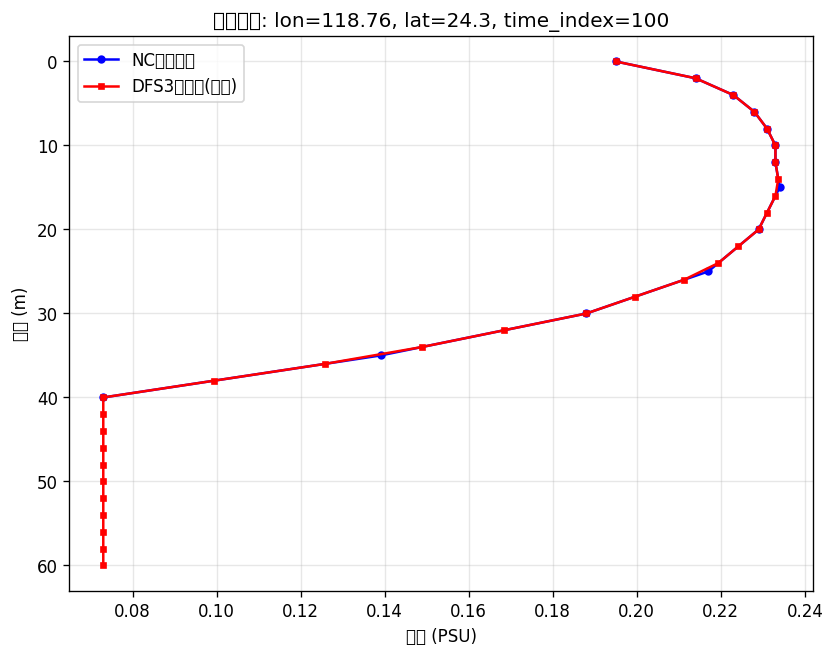

In [17]:
PROFILE_LON = 118.76
PROFILE_LAT = 24.30
PROFILE_TIME_INDEX = 100

ds_small = nc.Dataset(OUTPUT_NC_FILE, 'r')
ds_small.set_auto_mask(False)
ds_small.set_auto_scale(False)

lon_nc = np.array(ds_small.variables['lon'][:], dtype=np.float32)
lat_nc = np.array(ds_small.variables['lat'][:], dtype=np.float32)
depth_nc = np.array(ds_small.variables['depth'][:], dtype=np.float32)
u_nc = ds_small.variables['water_u']

i_nc, j_nc = nearest_ij(lon_nc, lat_nc, PROFILE_LON, PROFILE_LAT)
lon_nc_point = lon_nc[i_nc]
lat_nc_point = lat_nc[j_nc]

profile_nc = np.array(u_nc[PROFILE_TIME_INDEX, :, j_nc, i_nc], dtype=np.float32)

dfs3_data = mikeio.open(OUTPUT_DFS3_FILE)
depth_dfs3 = dfs3_data.geometry.z

data_dfs3 = dfs3_data.read(time=PROFILE_TIME_INDEX)
profile_dfs3 = np.array(data_dfs3[0].values[:, j_nc, i_nc], dtype=np.float32)
profile_dfs3_flipped = profile_dfs3[::-1]

print(f'检查点信息:')
print(f'  目标坐标: lon={PROFILE_LON}, lat={PROFILE_LAT}')
print(f'  NC最近点: lon={lon_nc_point:.6f}, lat={lat_nc_point:.6f}, i={i_nc}, j={j_nc}')
print(f'')
print(f'NC文件:')
print(f'  深度层数: {len(depth_nc)}')
print(f'  有效数据层数: {np.isfinite(profile_nc).sum()}')
print(f'  深度范围: {depth_nc.min():.1f} - {depth_nc.max():.1f} m')
print(f'  盐度范围: {np.nanmin(profile_nc):.3f} - {np.nanmax(profile_nc):.3f} PSU')
print(f'')
print(f'DFS3文件:')
print(f'  深度层数: {len(depth_dfs3)}')
print(f'  有效数据层数: {np.isfinite(profile_dfs3).sum()}')
print(f'  深度范围: {depth_dfs3.min():.1f} - {depth_dfs3.max():.1f} m')
print(f'  盐度范围: {np.nanmin(profile_dfs3):.3f} - {np.nanmax(profile_dfs3):.3f} PSU')

plt.figure(figsize=(8, 6))
plt.plot(profile_nc, depth_nc, 'o-', color='blue', label='NC原始剖面', markersize=4)
plt.plot(profile_dfs3_flipped, depth_dfs3, 's-', color='red', label='DFS3插值后(反转)', markersize=3)
plt.gca().invert_yaxis()
plt.xlabel('盐度 (PSU)')
plt.ylabel('深度 (m)')
plt.title(f'剖面对比: lon={PROFILE_LON}, lat={PROFILE_LAT}, time_index={PROFILE_TIME_INDEX}')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

ds_small.close()

In [15]:
dfs3_check = mikeio.open(OUTPUT_DFS3_FILE)
print('DFS3文件验证')
print(f'  文件大小: {os.path.getsize(OUTPUT_DFS3_FILE)/1024/1024:.2f} MB')
print(f'  时间步数: {dfs3_check.n_timesteps}')
print(f'  深度层数: {len(dfs3_check.geometry.z)}')
print(f'  深度第1层(表层): {dfs3_check.geometry.z[0]}m')
print(f'  经度间隔: {np.diff(dfs3_check.geometry.x)[0]:.6f}')
print(f'  纬度间隔: {np.diff(dfs3_check.geometry.y)[0]:.6f}')

# 修复：调用 .values 提取 numpy 数组以避免 np.nanmin 函数抛出 AttributeError
data_sample = dfs3_check.read(time=0)[0].values

# 修复：打印信息修改为盐度范围及单位 PSU
print(f'  盐度范围: {np.nanmin(data_sample):.2f} - {np.nanmax(data_sample):.2f} PSU')
print(f'  NaN比例: {np.isnan(data_sample).sum() / data_sample.size * 100:.2f}%')


DFS3文件验证
  文件大小: 140.91 MB
  时间步数: 2920
  深度层数: 31
  深度第1层(表层): 0.0m
  经度间隔: 0.080000
  纬度间隔: 0.040000
  盐度范围: 32.46 - 34.57 PSU
  NaN比例: 42.16%
